# 07 — Phân tích khám phá bối cảnh kinh tế vĩ mô

## Phạm vi phân tích

Notebook mô tả bối cảnh vĩ mô theo thời gian và sự khác biệt giữa các quốc gia, nền kinh tế, vùng lãnh thổ. H08 dùng dữ liệu tháng trong khoảng **01/2013–04/2026**; H09 và H10 dùng lát cắt **năm 2023**.

Dữ liệu tháng được đọc từ `fact_macro_monthly`, còn dữ liệu quốc gia được đọc từ `fact_country_yearly`. Các chuỗi có đơn vị khác nhau được vẽ trong các ô riêng có chung trục thời gian. Phân tích quốc gia giữ đơn vị ISO3–năm, không ghép với dữ liệu tiền điện tử.

Khác biệt về rổ CPI và phương pháp thống kê giới hạn việc so sánh lạm phát giữa các nền kinh tế. Các hình mô tả bối cảnh kinh tế, không đo mức sử dụng tiền điện tử hoặc kiểm định quan hệ của tiền điện tử với vĩ mô.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd() / "scripts"))
from common import TABLES, FIGURES, QUALITY, ensure_output_dirs, write_csv_atomic
ensure_output_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":180, "font.family":"DejaVu Sans"})
macro = pd.read_csv(TABLES / "fact_macro_monthly.csv", parse_dates=["month"])
country = pd.read_csv(TABLES / "fact_country_yearly.csv", keep_default_na=False, na_values=[""])

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show(); plt.close(fig)

## H08 — Diễn biến các chỉ tiêu vĩ mô theo tháng

Bốn ô biểu đồ lần lượt thể hiện VIX trung bình tháng, DXY dựng lại từ giá trị hợp lệ cuối cùng trong tháng, lạm phát CPI Mỹ YoY và lợi suất trái phiếu Kho bạc Mỹ kỳ hạn 10 năm.

Các ô dùng chung trục thời gian nhưng giữ trục giá trị riêng, phù hợp với đơn vị và thang đo khác nhau. Cách trình bày này giúp quan sát từng chuỗi trong cùng giai đoạn 01/2013–04/2026 mà không tạo một thang giá trị chung thiếu ý nghĩa.

Hình dùng mức hoặc tỷ lệ của chỉ tiêu để mô tả bối cảnh, không phải các biến thay đổi dùng cho ma trận tương quan ở notebook 08. DXY mang nhãn dựng lại; khóa cuối tháng chỉ là quy ước nối, không bảo đảm các nguồn được quan sát tại cùng một ngày.

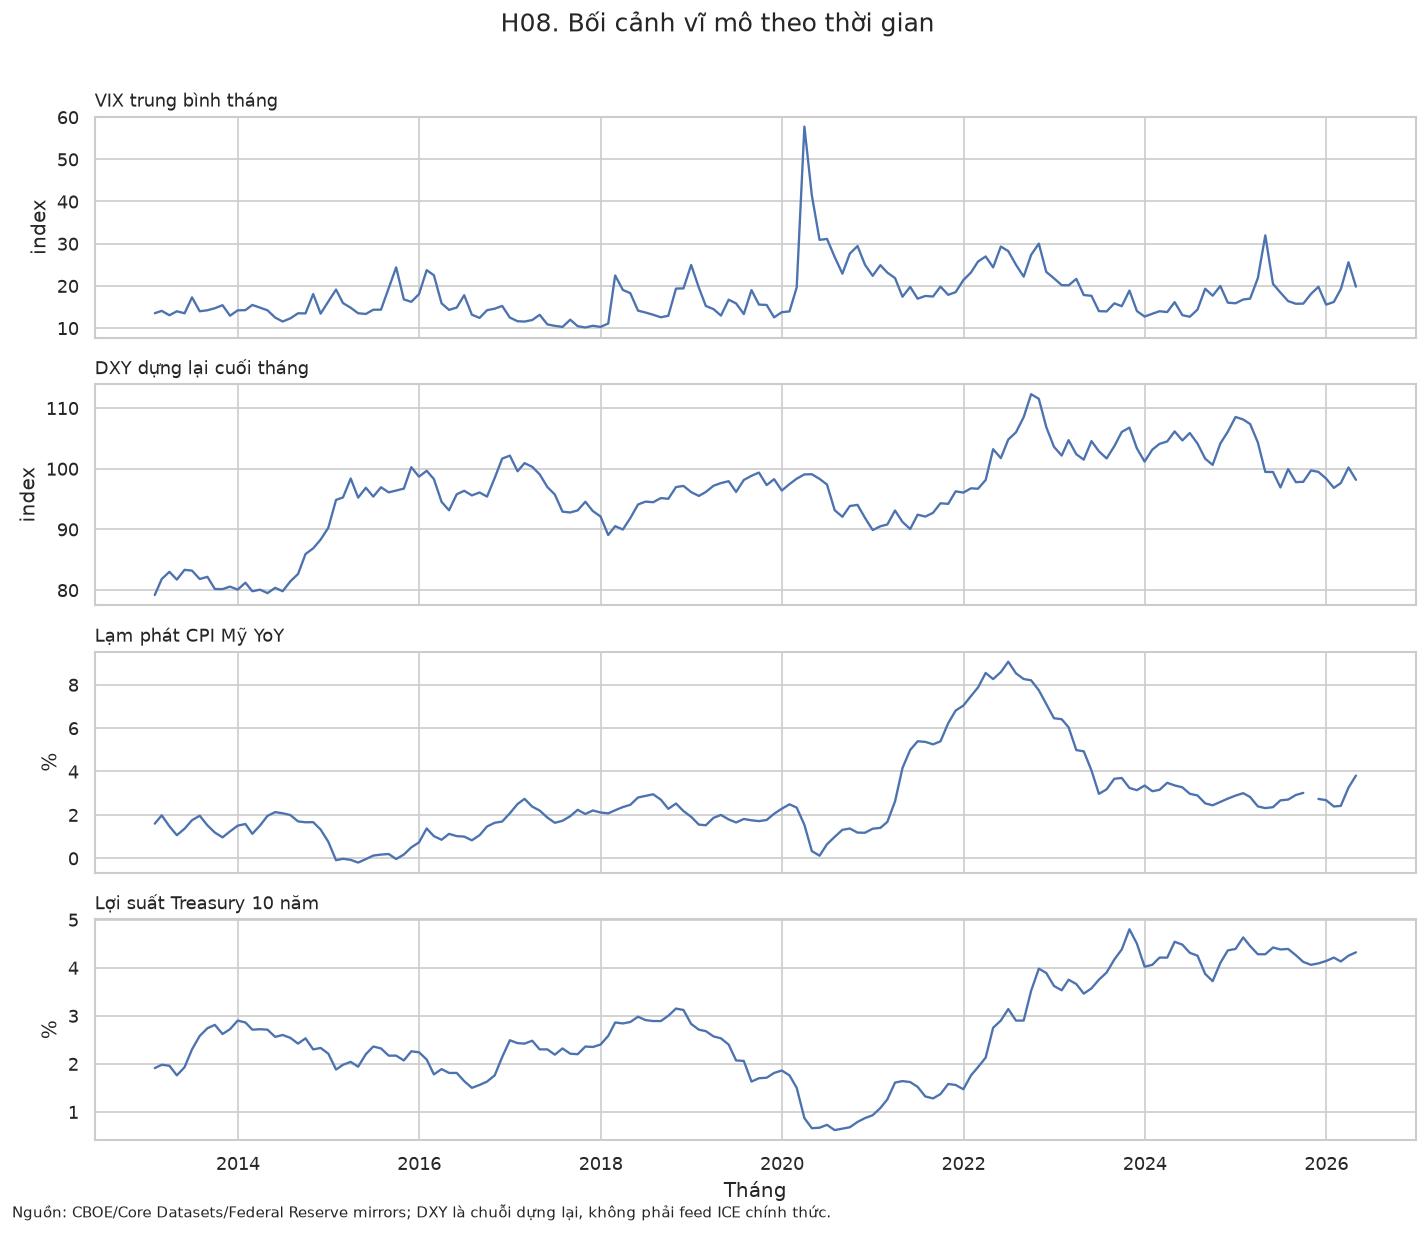

In [2]:
view = macro.loc[macro.month.between("2013-01-31", "2026-04-30")]
series = [
    ("vix_mean","VIX trung bình tháng","index"),
    ("dxy_reconstructed","DXY dựng lại cuối tháng","index"),
    ("cpi_yoy_pct","Lạm phát CPI Mỹ YoY","%"),
    ("us10y_yield_pct","Lợi suất Treasury 10 năm","%"),
]
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, (col, title, unit) in zip(axes, series):
    ax.plot(view.month, view[col], linewidth=1.4)
    ax.set_ylabel(unit); ax.set_title(title, loc="left", fontsize=11)
axes[-1].set_xlabel("Tháng")
fig.suptitle("H08. Bối cảnh vĩ mô theo thời gian", y=1.01, fontsize=15)
fig.text(.01, .005, "Nguồn: CBOE/Core Datasets/Federal Reserve mirrors; DXY là chuỗi dựng lại, không phải feed ICE chính thức.", fontsize=9)
save(fig, "H08_boi_canh_vi_mo_small_multiples.png")

## H09 — Phân phối lạm phát theo châu lục năm 2023

Mỗi điểm đại diện cho một mã ISO3 có số liệu lạm phát năm 2023. Boxplot tóm tắt trung vị và khoảng tứ phân vị của từng châu lục; các châu lục được sắp theo trung vị lạm phát. Điểm được vẽ thêm để thể hiện các quan sát, kể cả ngoại lệ mà lớp boxplot không hiển thị riêng.

Trục `symlog` dùng thang tuyến tính quanh 0 với ngưỡng 5, và thang log đối xứng ở hai phía ngoài vùng đó. Nhờ vậy hình giữ được cả giảm phát, mức lạm phát thông thường và các giá trị cực đoan. Đường 10% là mốc mô tả của dự án.

Các nền kinh tế có trọng số như nhau trong hình; đây không phải lạm phát trung bình có trọng số dân số hoặc GDP của châu lục. Kết quả chỉ phản ánh các đơn vị có dữ liệu, và cần đọc cùng khác biệt phương pháp đo CPI.

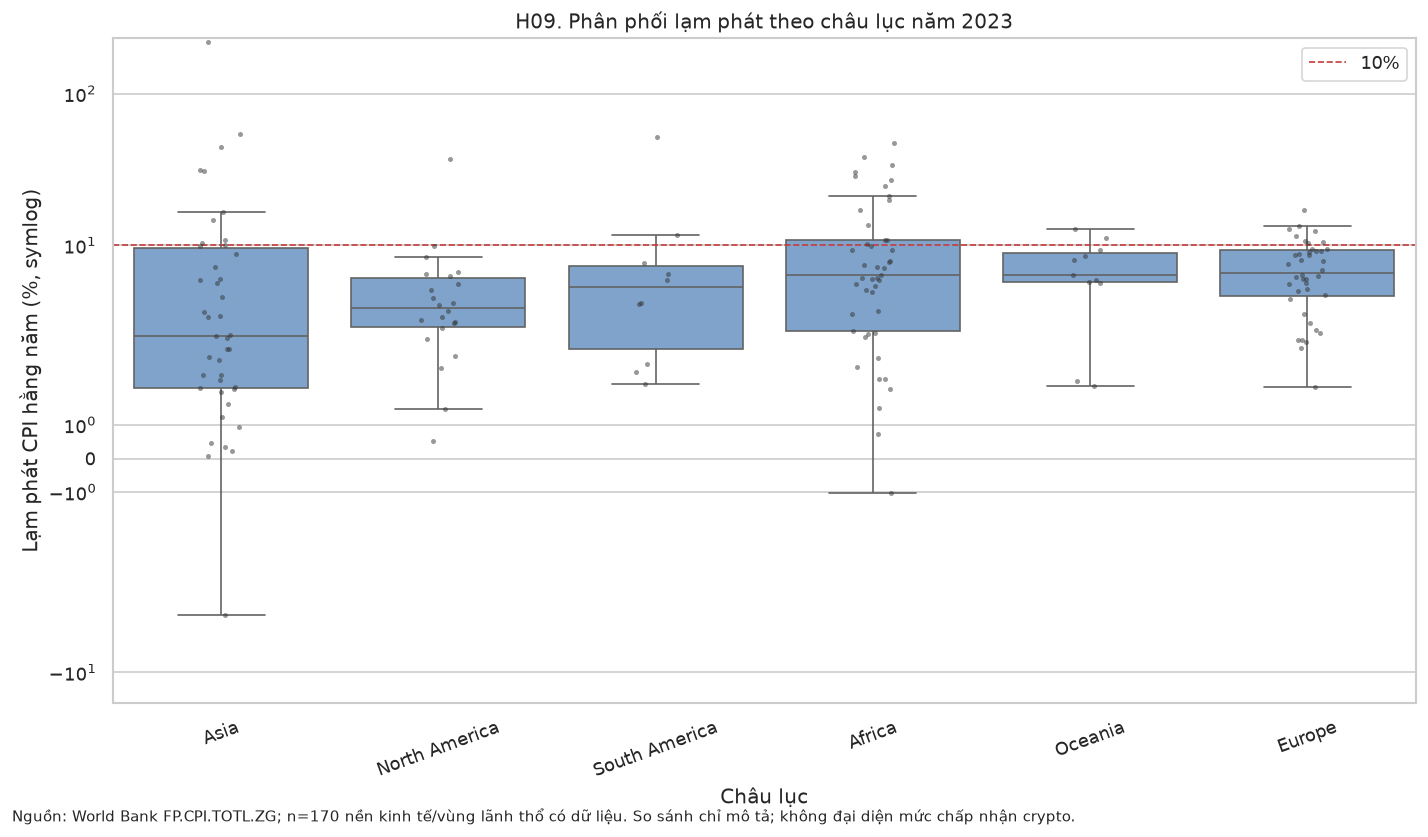

In [3]:
c2023 = country.loc[(country.year.astype(int) == 2023) & country.inflation_annual_pct.notna()].copy()
order = c2023.groupby("continent_name").inflation_annual_pct.median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=c2023, x="continent_name", y="inflation_annual_pct", order=order, showfliers=False, color="#73A2D6", ax=ax)
sns.stripplot(data=c2023, x="continent_name", y="inflation_annual_pct", order=order, color="#333333", alpha=.5, size=3, ax=ax)
ax.axhline(10, color="#C43D3D", linestyle="--", linewidth=1, label="10%")
ax.set_yscale("symlog", linthresh=5)
ax.set_title("H09. Phân phối lạm phát theo châu lục năm 2023")
ax.set_xlabel("Châu lục"); ax.set_ylabel("Lạm phát CPI hằng năm (%, symlog)"); ax.legend()
ax.tick_params(axis="x", rotation=20)
fig.text(.01, .01, f"Nguồn: World Bank FP.CPI.TOTL.ZG; n={len(c2023)} nền kinh tế/vùng lãnh thổ có dữ liệu. So sánh chỉ mô tả; không đại diện mức chấp nhận crypto.", fontsize=9)
save(fig, "H09_lam_phat_quoc_gia_2023.png")

## H10 — GDP bình quân đầu người và lạm phát năm 2023

Mỗi điểm là một quốc gia, nền kinh tế hoặc vùng lãnh thổ có đủ GDP/người và lạm phát trong năm 2023. GDP/người bằng GDP theo USD hiện hành chia cho dân số cùng năm; màu điểm thể hiện châu lục.

Trục GDP/người dùng thang log vì giá trị chênh lệch lớn giữa các đơn vị. Trục lạm phát dùng `symlog` để giữ cả giá trị âm và cực đoan. Scatter giúp quan sát độ phân tán và các điểm khác biệt trong lát cắt cùng năm.

Hình mô tả mối liên hệ cắt ngang của hai chỉ tiêu, không chứng minh GDP/người gây ra lạm phát. Mẫu này cũng khác H09 vì chỉ giữ đơn vị đủ cả hai chỉ tiêu.

Phần tổng hợp bên dưới lưu `eda_macro_context_2023.csv`, gồm số nền kinh tế, trung vị lạm phát, số đơn vị có lạm phát từ 10% và số quan sát cực đoan theo từng châu lục. Bảng tổng hợp dùng mẫu lạm phát của H09, không phải mẫu đủ hai biến của H10.

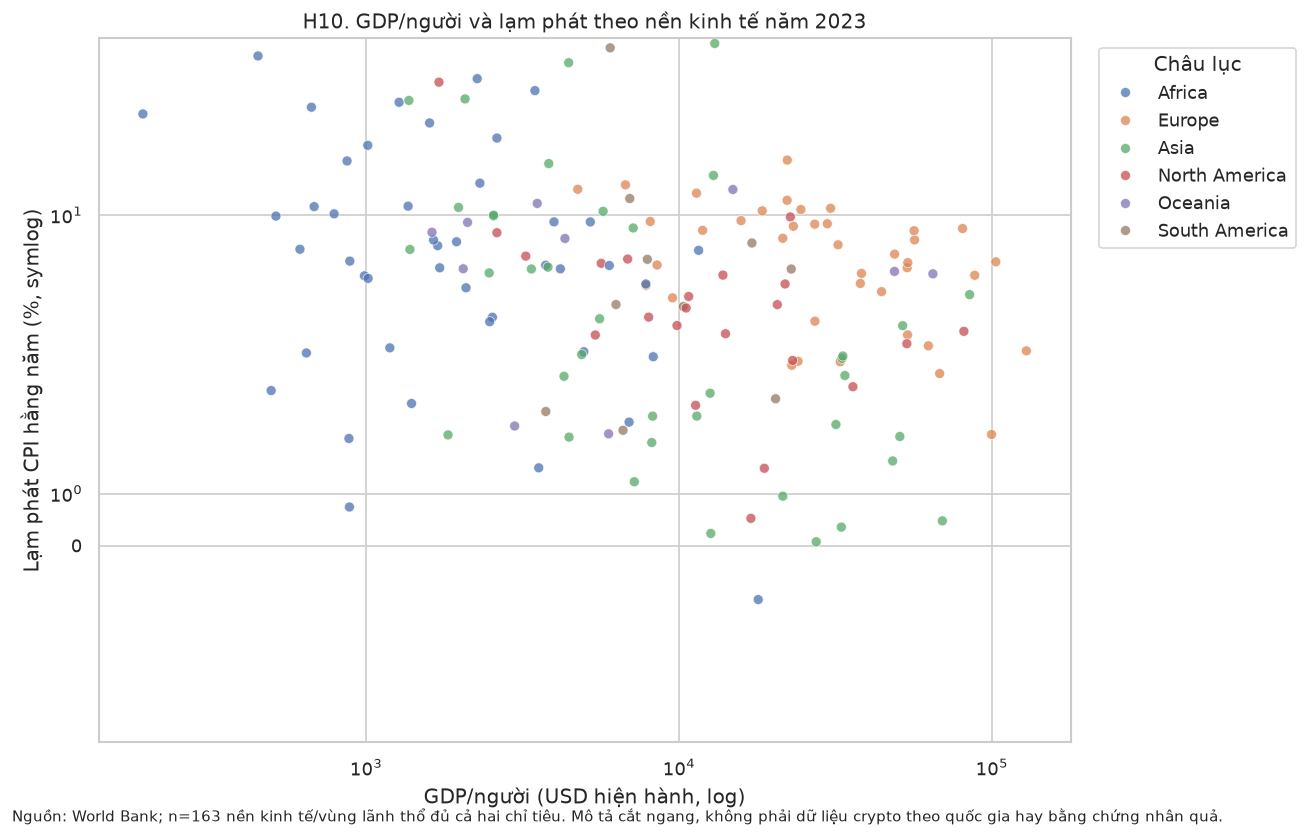

In [4]:
cross = country.loc[(country.year.astype(int) == 2023) & country.gdp_per_capita_usd.notna() & country.inflation_annual_pct.notna()].copy()
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=cross, x="gdp_per_capita_usd", y="inflation_annual_pct", hue="continent_name", alpha=.75, ax=ax)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=5)
ax.set_title("H10. GDP/người và lạm phát theo nền kinh tế năm 2023")
ax.set_xlabel("GDP/người (USD hiện hành, log)"); ax.set_ylabel("Lạm phát CPI hằng năm (%, symlog)")
ax.legend(title="Châu lục", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.text(.01, .01, f"Nguồn: World Bank; n={len(cross)} nền kinh tế/vùng lãnh thổ đủ cả hai chỉ tiêu. Mô tả cắt ngang, không phải dữ liệu crypto theo quốc gia hay bằng chứng nhân quả.", fontsize=9)
save(fig, "H10_gdp_lam_phat_2023.png")

In [5]:
context_summary = c2023.groupby("continent_name").agg(
    economies=("iso3", "nunique"),
    median_inflation_pct=("inflation_annual_pct", "median"),
    high_inflation_economies=("high_inflation_ge_10pct", "sum"),
    retained_extreme_inflation=("inflation_extreme_flag", "sum"),
).reset_index()
write_csv_atomic(context_summary, QUALITY / "eda_macro_context_2023.csv")
display(context_summary)

,continent_name,economies,median_inflation_pct,high_inflation_economies,retained_extreme_inflation
0,Africa,45,6.342217,14,0
1,Asia,42,3.656148,9,1
2,Europe,40,6.546696,8,0
3,North America,22,4.477209,1,0
4,Oceania,11,6.351130,2,0
5,South America,10,5.250563,2,0
